# Practice Exam 2 — Steel Industry Energy (SOLUTION)
Exam layout (from both instruction sheets):

| Part | Task | Points |
|---|---|---|
| 1 Regression **from scratch** | 1.1 train 4 models (Linear, Multiple, Polynomial, Best) + predict | 8 |
| | 1.2 compare R² and rank the models + predict the given value | 2 |
| 2 Classification **with library** | 2.1 train 4+ classifiers | 8 |
| | 2.2 compare accuracy and F1, rank them | 2 |
| | 2.3 use the regression predictions to predict the class | 3 |

Dataset: **UCI Steel Industry Energy Consumption (35,040 rows, numeric + text columns)**. Regression target: `Usage_kWh`. Classification target: `Load_Type` (3 classes: Light / Medium / Maximum load).

## 0. Load and prepare the data

In [1]:
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # silences a harmless joblib warning on Windows
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
np.set_printoptions(suppress=True, precision=4)

In [2]:
df = pd.read_csv('data/Steel_industry_data.csv')
print(df.shape)
df.head()

(35040, 11)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


In [3]:
print(df.isnull().sum().sum(), "missing values")
print(df.dtypes.value_counts())
df.describe().T.head(15)

0 missing values
float64    6
str        4
int64      1
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Usage_kWh,35040.0,27.386892,33.444380,0.0,3.20,4.57,51.2375,157.18
Lagging_Current_Reactive.Power_kVarh,35040.0,13.035384,16.306000,0.0,2.30,5.00,22.6400,96.91
Leading_Current_Reactive_Power_kVarh,35040.0,3.870949,7.424463,0.0,0.00,0.00,2.0900,27.76
CO2(tCO2),35040.0,0.011524,0.016151,0.0,0.00,0.00,0.0200,0.07
Lagging_Current_Power_Factor,35040.0,80.578056,18.921322,0.0,63.32,87.96,99.0225,100.00
Leading_Current_Power_Factor,35040.0,84.367870,30.456535,0.0,99.70,100.00,100.0000,100.00
NSM,35040.0,42750.000000,24940.534317,0.0,21375.00,42750.00,64125.0000,85500.00


In [4]:
TARGET = "Usage_kWh"
df = df.dropna()
# feature engineering: NSM = seconds since midnight -> hour of day is easier to learn
df["hour"] = df["NSM"] / 3600
X_df = df.drop(columns=[TARGET, "date", "Load_Type", "NSM"])   # Load_Type is the Part-2 label: never use it as input
X_df = pd.get_dummies(X_df, drop_first=True).astype(float)      # WeekStatus, Day_of_week -> 0/1 columns
feature_names = list(X_df.columns)
X = X_df.values
y = df[TARGET].values.astype(float)
print(len(feature_names), "features:", feature_names)

13 features: ['Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'hour', 'WeekStatus_Weekend', 'Day_of_week_Monday', 'Day_of_week_Saturday', 'Day_of_week_Sunday', 'Day_of_week_Thursday', 'Day_of_week_Tuesday', 'Day_of_week_Wednesday']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# numpy-only alternative:
# idx = np.random.default_rng(42).permutation(len(X)); n_te = int(0.2 * len(X))
# X_test, X_train, y_test, y_train = X[idx[:n_te]], X[idx[n_te:]], y[idx[:n_te]], y[idx[n_te:]]
print(X_train.shape, X_test.shape)

(28032, 13) (7008, 13)


In [6]:
mu, sd = X_train.mean(0), X_train.std(0)
sd[sd == 0] = 1                       # constant column -> avoid divide by zero
Xtr = (X_train - mu) / sd
Xte = (X_test - mu) / sd

---
# Part 1 — Regression from scratch
## 1.1 The from-scratch toolbox

In [7]:
# ===== from-scratch toolbox (numpy only) =====
def r2_scratch(y, p):
    ss_res = ((y - p) ** 2).sum()          # error left over by the model
    ss_tot = ((y - y.mean()) ** 2).sum()   # error of "always guess the mean"
    return 1 - ss_res / ss_tot

def rmse_scratch(y, p):
    return np.sqrt(((y - p) ** 2).mean())

def add_bias(X):
    return np.c_[np.ones(len(X)), X]      # column of 1s -> intercept theta0

class LinearRegressionScratch:
    """y_hat = X @ theta.  method='ols' (normal equation) or 'gd' (gradient descent).
    lam > 0 adds Ridge (L2) penalty -> stops huge weights / overfitting."""
    def __init__(self, method="ols", lr=0.05, epochs=2000, lam=0.0):
        self.method, self.lr, self.epochs, self.lam = method, lr, epochs, lam
    def fit(self, X, y):
        Xb = add_bias(X)
        n, d = Xb.shape
        if self.method == "ols":
            I = np.eye(d); I[0, 0] = 0          # never penalise the intercept
            self.theta = np.linalg.solve(Xb.T @ Xb + self.lam * I, Xb.T @ y)
        else:
            self.theta = np.zeros(d)
            self.loss_history = []
            for _ in range(self.epochs):
                error = Xb @ self.theta - y               # prediction - truth
                grad = (2 / n) * Xb.T @ error              # d(MSE)/d(theta)
                grad[1:] += 2 * self.lam * self.theta[1:] / n
                self.theta -= self.lr * grad               # step downhill
                self.loss_history.append((error ** 2).mean())
        return self
    def predict(self, X):
        return add_bias(X) @ self.theta

def poly_features(X, degree=2):
    """degree 2: x_i, all x_i*x_j (incl. squares). degree 3: also adds x_i^3."""
    parts = [X]
    n = X.shape[1]
    if degree >= 2:
        parts.append(np.column_stack([X[:, i] * X[:, j] for i in range(n) for j in range(i, n)]))
    if degree >= 3:
        parts.append(X ** 3)
    return np.hstack(parts)

class PolyRegressionScratch:
    def __init__(self, degree=2, lam=1.0):
        self.degree, self.lam = degree, lam
    def fit(self, X, y):
        P = poly_features(X, self.degree)
        self.mu, self.sd = P.mean(0), P.std(0) + 1e-12   # re-scale new columns
        self.lin = LinearRegressionScratch("ols", lam=self.lam).fit((P - self.mu) / self.sd, y)
        return self
    def predict(self, X):
        return self.lin.predict((poly_features(X, self.degree) - self.mu) / self.sd)

class KNNRegressorScratch:
    """Predict = distance-weighted average of the k closest training points."""
    def __init__(self, k=10):
        self.k = k
    def fit(self, X, y):
        self.X, self.y = X, y
        return self
    def predict(self, X):
        out = []
        sq_train = (self.X ** 2).sum(1)
        for i in range(0, len(X), 1000):                       # chunks -> low memory
            A = X[i:i + 1000]
            d2 = (A ** 2).sum(1)[:, None] + sq_train[None, :] - 2 * A @ self.X.T
            d2 = np.maximum(d2, 0)
            nn = np.argpartition(d2, self.k, axis=1)[:, :self.k]
            w = 1 / (np.sqrt(np.take_along_axis(d2, nn, 1)) + 1e-9)
            out.append((self.y[nn] * w).sum(1) / w.sum(1))
        return np.concatenate(out)

class BlendScratch:
    """Best model: weighted average of PolyRidge + KNN.  Two different kinds of model
    make different mistakes, so averaging cancels part of the error (ensemble idea)."""
    def __init__(self, degree=2, lam=10.0, k=15, w=0.5):
        self.poly, self.knn, self.w = PolyRegressionScratch(degree, lam), KNNRegressorScratch(k), w
    def fit(self, X, y):
        self.poly.fit(X, y); self.knn.fit(X, y)
        return self
    def predict(self, X):
        return self.w * self.poly.predict(X) + (1 - self.w) * self.knn.predict(X)

### Model 1 — Simple Linear Regression (1 feature, gradient descent)

best single feature: CO2(tCO2) | corr = 0.987
GD  theta: [27.2861 32.9551]
OLS theta: [27.2861 32.9551]  <- should match


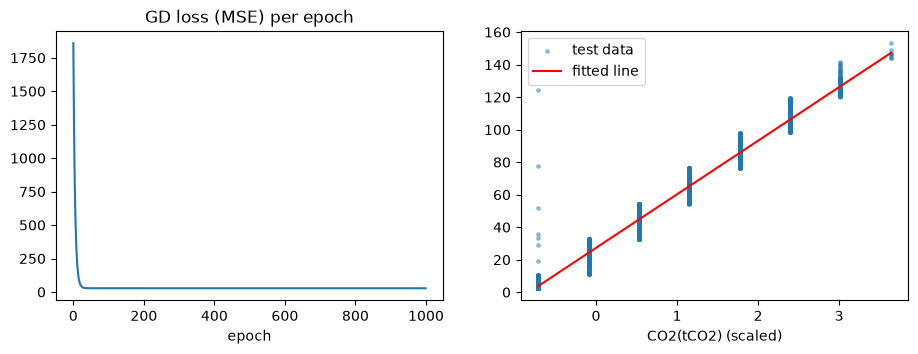

In [8]:
corr = [abs(np.corrcoef(Xtr[:, j], y_train)[0, 1]) for j in range(Xtr.shape[1])]
best_j = int(np.argmax(corr))
print("best single feature:", feature_names[best_j], "| corr = %.3f" % corr[best_j])

m1 = LinearRegressionScratch("gd", lr=0.05, epochs=1000).fit(Xtr[:, [best_j]], y_train)
m1_check = LinearRegressionScratch("ols").fit(Xtr[:, [best_j]], y_train)
print("GD  theta:", m1.theta)
print("OLS theta:", m1_check.theta, " <- should match")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(m1.loss_history); ax[0].set_title("GD loss (MSE) per epoch"); ax[0].set_xlabel("epoch")
ax[1].scatter(Xte[:, best_j], y_test, s=6, alpha=.4, label="test data")
xs = np.linspace(Xte[:, best_j].min(), Xte[:, best_j].max(), 50)
ax[1].plot(xs, m1.predict(xs[:, None]), "r", label="fitted line"); ax[1].legend()
ax[1].set_xlabel(feature_names[best_j] + " (scaled)"); plt.show()

### Model 2 — Multiple Linear Regression (all features)

In [9]:
m2 = LinearRegressionScratch("ols").fit(Xtr, y_train)
print("intercept:", round(m2.theta[0], 4))
print(pd.Series(m2.theta[1:], index=feature_names).sort_values(key=abs, ascending=False).head(8))

intercept: 27.2861
WeekStatus_Weekend                     -84.325993
Day_of_week_Saturday                    65.328201
Day_of_week_Sunday                      65.263281
CO2(tCO2)                               26.792831
Lagging_Current_Reactive.Power_kVarh     5.198412
Lagging_Current_Power_Factor             2.526042
Leading_Current_Power_Factor             2.370005
Leading_Current_Reactive_Power_kVarh     1.016761
dtype: float64


### Model 3 — Polynomial Regression (degree 2)

In [10]:
m3 = PolyRegressionScratch(degree=2, lam=1.0).fit(Xtr, y_train)
print("number of polynomial features:", poly_features(Xtr[:2], 2).shape[1])

number of polynomial features: 104


### Model 4 — Best model: PolyRidge + KNN blend (tuned)

In [11]:
# tune the Blend on a VALIDATION split carved out of TRAIN (the test set stays untouched)
Xa, Xv, ya, yv = train_test_split(Xtr, y_train, test_size=0.2, random_state=0)
best = (-np.inf, None)
for lam in [1, 10, 100]:
    p_poly = PolyRegressionScratch(2, lam).fit(Xa, ya).predict(Xv)
    for k in [5, 10, 15, 25]:
        p_knn = KNNRegressorScratch(k).fit(Xa, ya).predict(Xv)
        for w in [0, 0.3, 0.5, 0.7, 1]:
            score = r2_scratch(yv, w * p_poly + (1 - w) * p_knn)
            if score > best[0]:
                best = (score, dict(lam=lam, k=k, w=w))
print("best validation R2 = %.4f with %s" % best)
m4 = BlendScratch(degree=2, **best[1]).fit(Xtr, y_train)   # refit on ALL training data

best validation R2 = 0.9968 with {'lam': 1, 'k': 5, 'w': 0.7}


## 1.2 Predict and compare R² (ranking)

,rank,model,R2,RMSE
3,1,4 Best: Blend Poly+KNN,0.996848,1.892889
2,2,3 Polynomial deg2,0.996295,2.052280
1,3,2 Multiple Linear (OLS),0.984194,4.238740
0,4,"1 Linear (1 feature, GD)",0.982372,4.476363


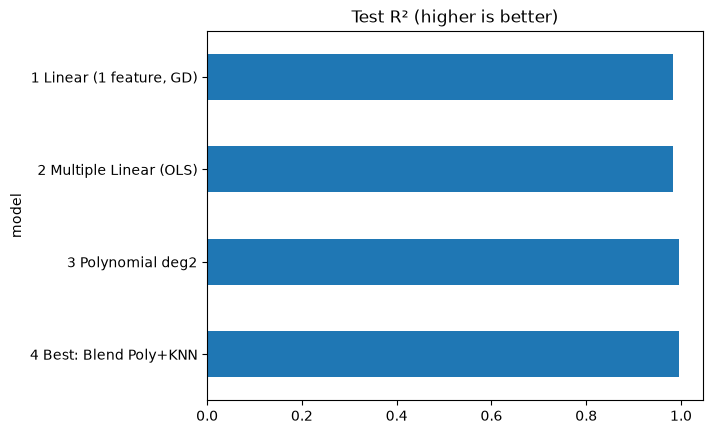

In [12]:
preds_reg = {
    "1 Linear (1 feature, GD)": m1.predict(Xte[:, [best_j]]),
    "2 Multiple Linear (OLS)": m2.predict(Xte),
    "3 Polynomial deg2": m3.predict(Xte),
    "4 Best: Blend Poly+KNN": m4.predict(Xte),
}
rows = [(name, r2_scratch(y_test, p), rmse_scratch(y_test, p)) for name, p in preds_reg.items()]
table_reg = pd.DataFrame(rows, columns=["model", "R2", "RMSE"]).sort_values("R2", ascending=False)
table_reg.insert(0, "rank", range(1, len(table_reg) + 1))
display(table_reg)
table_reg.plot.barh(x="model", y="R2", legend=False, title="Test R² (higher is better)"); plt.show()

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
print("sklearn R2 :", r2_score(y_test, LinearRegression().fit(Xtr, y_train).predict(Xte)))
print("scratch R2 :", r2_scratch(y_test, preds_reg["2 Multiple Linear (OLS)"]))

sklearn R2 : 0.9841941048149219
scratch R2 : 0.984194104814922


### Predict the value the teacher gives (ค่าที่ให้)

In [14]:
def make_row(values: dict):
    raw = pd.DataFrame([values])
    raw = pd.get_dummies(raw).reindex(columns=feature_names, fill_value=0).astype(float)
    for c in feature_names:                      # columns not given -> training mean
        if c not in values and not any(c.startswith(k + "_") for k in values):
            raw[c] = X_train[:, feature_names.index(c)].mean()
    return (raw.values - mu) / sd

given = {"Lagging_Current_Reactive.Power_kVarh": 20.0, "Leading_Current_Reactive_Power_kVarh": 0.0,
         "CO2(tCO2)": 0.02, "Lagging_Current_Power_Factor": 85.0, "Leading_Current_Power_Factor": 100.0,
         "hour": 10.5, "WeekStatus": "Weekday", "Day_of_week": "Tuesday"}
x_new = make_row(given)
for name, m in [("1 Linear", m1), ("2 Multiple", m2), ("3 Polynomial", m3), ("4 Best", m4)]:
    xin = x_new[:, [best_j]] if name.startswith("1") else x_new
    print(f"{name:14s} -> predicted Usage_kWh = {m.predict(xin)[0]:.3f}")

1 Linear       -> predicted Usage_kWh = 44.760
2 Multiple     -> predicted Usage_kWh = 45.585
3 Polynomial   -> predicted Usage_kWh = 32.713
4 Best         -> predicted Usage_kWh = 35.277


---
# Part 2 — Classification with library (sklearn)
## 2.1 Build the class label and train classifiers

In [15]:
y_cls = np.array(df["Load_Type"].tolist())   # plain numpy array of strings
print(pd.Series(y_cls).value_counts())

Light_Load      18072
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64


In [16]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, y_cls, test_size=0.2, random_state=42)
print(pd.Series(yc_train).value_counts(normalize=True).round(3))

Light_Load      0.517
Medium_Load     0.277
Maximum_Load    0.206
Name: proportion, dtype: float64


In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [18]:
classifiers = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN (k=15)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15, weights="distance")),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=3, gamma="scale")),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}
for name, model in classifiers.items():
    model.fit(Xc_train, yc_train)
    print("trained", name)

trained Logistic Regression
trained KNN (k=15)


trained SVM (RBF)
trained Decision Tree


trained Random Forest


### Best classifier — tuned with cross-validation

In [19]:
grid = GridSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    {"learning_rate": [0.05, 0.1], "max_depth": [None, 6], "max_iter": [200, 400]},
    cv=5, scoring="f1_macro", n_jobs=-1)
grid.fit(Xc_train, yc_train)
print("best params:", grid.best_params_, "| CV F1 = %.4f" % grid.best_score_)
classifiers["Best: tuned Gradient Boosting"] = grid.best_estimator_

best params: {'learning_rate': 0.1, 'max_depth': None, 'max_iter': 200} | CV F1 = 0.8791


## 2.2 Predict and compare accuracy and F1 (ranking)

,rank,model,accuracy,F1
4,1,Random Forest,0.901684,0.875294
5,2,Best: tuned Gradient Boosting,0.899686,0.872665
3,3,Decision Tree,0.872003,0.840545
1,4,KNN (k=15),0.854167,0.819324
2,5,SVM (RBF),0.811787,0.764710
0,6,Logistic Regression,0.756421,0.702694


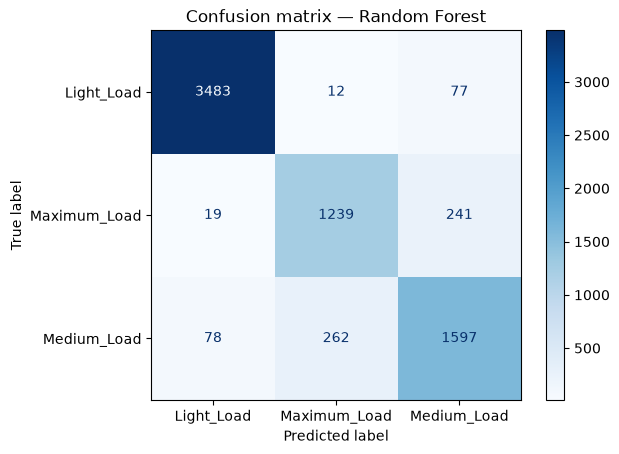

              precision    recall  f1-score   support

  Light_Load       0.97      0.98      0.97      3572
Maximum_Load       0.82      0.83      0.82      1499
 Medium_Load       0.83      0.82      0.83      1937

    accuracy                           0.90      7008
   macro avg       0.88      0.88      0.88      7008
weighted avg       0.90      0.90      0.90      7008



In [20]:
avg = "binary" if len(np.unique(y_cls)) == 2 else "macro"
preds_cls = {name: m.predict(Xc_test) for name, m in classifiers.items()}
rows = [(n, accuracy_score(yc_test, p), f1_score(yc_test, p, average=avg)) for n, p in preds_cls.items()]
table_cls = pd.DataFrame(rows, columns=["model", "accuracy", "F1"]).sort_values("F1", ascending=False)
table_cls.insert(0, "rank", range(1, len(table_cls) + 1))
display(table_cls)

best_name = table_cls.iloc[0]["model"]
ConfusionMatrixDisplay.from_predictions(yc_test, preds_cls[best_name], cmap="Blues")
plt.title("Confusion matrix — " + best_name); plt.show()
print(classification_report(yc_test, preds_cls[best_name]))

## 2.3 Use the regression predictions to predict the class

In [21]:
from sklearn.model_selection import KFold
oof = np.zeros(len(Xtr))
for tr_i, va_i in KFold(5, shuffle=True, random_state=42).split(Xtr):
    oof[va_i] = BlendScratch(2, **best[1]).fit(Xtr[tr_i], y_train[tr_i]).predict(Xtr[va_i])
X_stack_tr = np.c_[Xc_train, oof]
X_stack_te = np.c_[Xc_test, preds_reg["4 Best: Blend Poly+KNN"]]
rows = []
for name in ["Random Forest", "Best: tuned Gradient Boosting"]:
    from sklearn.base import clone
    m = clone(classifiers[name]).fit(X_stack_tr, yc_train)
    p = m.predict(X_stack_te)
    rows.append((name + " + regression feature", accuracy_score(yc_test, p), f1_score(yc_test, p, average="macro")))
table_23 = pd.concat([table_cls[["model", "accuracy", "F1"]],
                      pd.DataFrame(rows, columns=["model", "accuracy", "F1"])]).sort_values("F1", ascending=False)
table_23.insert(0, "rank", range(1, len(table_23) + 1))
display(table_23.reset_index(drop=True))

,rank,model,accuracy,F1
0,1,Random Forest + regression feature,0.903539,0.877224
1,2,Best: tuned Gradient Boosting + regression fea...,0.901541,0.875693
2,3,Random Forest,0.901684,0.875294
3,4,Best: tuned Gradient Boosting,0.899686,0.872665
4,5,Decision Tree,0.872003,0.840545
5,6,KNN (k=15),0.854167,0.819324
6,7,SVM (RBF),0.811787,0.764710
7,8,Logistic Regression,0.756421,0.702694


### Classify the teacher's given value

In [22]:
x_raw = make_row(given) * sd + mu             # back to unscaled (classifiers take raw X)
for name in table_cls["model"].head(3):
    print(f"{name:32s} -> class {classifiers[name].predict(x_raw)[0]}")

Random Forest                    -> class Maximum_Load
Best: tuned Gradient Boosting    -> class Maximum_Load
Decision Tree                    -> class Maximum_Load


---
### Exam checklist
1. Same `random_state=42` everywhere → fair comparison and reproducible numbers.
2. Never fit a scaler or tune anything on TEST.
3. Scratch Model 2 R² == sklearn `LinearRegression` R² → your OLS is correct.
4. Print a **ranked table** for Part 1 (R²) and Part 2 (accuracy and F1). That's the 2-point "compare/rank" item.
5. Write one sentence on *why* the winner wins. Teachers give marks for the reasoning.